# Hotel Booking Data Analysis

**Course:** Data Processing with Python (HAMK)

**Group members:**
1. Anup Kandel
2. Sandesh Bishokarma
3. Sushant Koirala
4. Tanka Raj Aryal

## Relationships and grouped analysis

Complete at least three grouped or two-variable analyses. Together they must include:
- one categorical-versus-categorical analysis using a crosstab;
- one categorical-versus-numerical analysis using `groupby()` and aggregation; and
- one numerical-versus-numerical or time-based analysis.

For crosstabs, show both counts and clearly labelled percentages. State what the percentage denominator is.

**Responsible:** Anup Kandel (time-based analysis for RQ3).

In [2]:
#RQ3 : How does booking volume vary by arrival month for each hotel?

import pandas as pd
import matplotlib.pyplot as plt

hotel_raw = pd.read_csv("../../data/hotel_bookings_final_project.csv")
hotel = hotel_raw.copy()

#creating the arrival and monthly booking counts
hotel["arrival_date"] = pd.to_datetime(
    hotel["arrival_date_year"].astype(str) + "-" + hotel["arrival_date_month"] + "-" +
    hotel["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")
hotel["arrival_month"] = hotel["arrival_date"].dt.month

monthly = hotel.groupby(["arrival_month", "hotel"]).size().unstack()

## Final visualizations

At least four finished visualizations (Matplotlib or Pandas plotting): one categorical comparison; one numerical distribution;
one relationship or grouped comparison; one time-based or multi-group figure.

Each needs a descriptive title, clear axis labels, a legend when needed, readable labels, sensible formatting, and the sample size (n).
After each, write a short **What can we observe?** paragraph without unsupported causal claims.

**Responsible:** Anup Kandel (Figure 4: time-based figure) and putting the final four together.

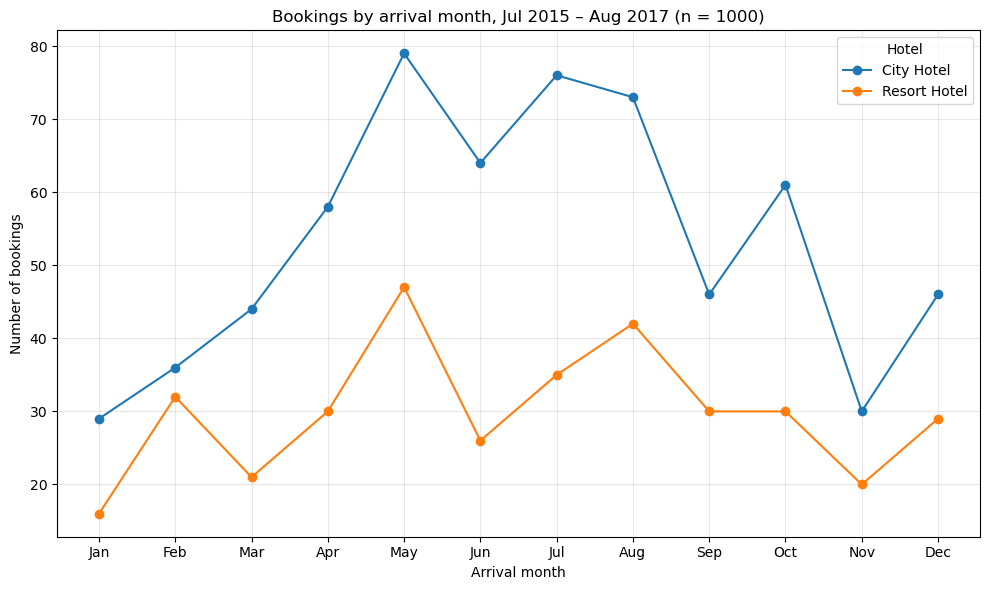

In [3]:
# Figure 4: Bookings by arrival month
ax = monthly.plot(marker="o", figsize=(10, 6))

ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

ax.set_xlabel("Arrival month")
ax.set_ylabel("Number of bookings")
ax.set_title(
    f"Bookings by arrival month, Jul 2015 – Aug 2017 "
    f"(n = {len(hotel)})"
)
ax.legend(title="Hotel")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


#Conclusion:
**What can we observe?**

The line chart compares monthly booking volume for the City Hotel and Resort Hotel. It helps identify the busiest and quietest arrival months and compare booking patterns between the two hotels.

The dataset covers July 2015 to August 2017, so the months do not all have equal coverage across years. July and August appear in all three years. The monthly totals should therefore be interpreted with caution. The complete year 2016 provides a more balanced comparison across all twelve months.

## Exports and verification

Export at least `hotel_bookings_cleaned.csv` (cleaned dataset) and `hotel_booking_summary.csv` (one useful summary table).
Read the exported files back into Python and verify their shape and key columns.

**Responsible:** Anup Kandel.

In [7]:
hotel.to_csv("../../outputs/hotel_bookings_cleaned.csv", index=False)

summary = hotel.groupby("hotel").agg(
    bookings=("is_canceled", "count"),
    cancellation_rate_pct=("is_canceled", "mean"),
    median_lead_time=("lead_time", "median"),
    median_adr=("average_daily_rate", "median"),
).reset_index()

summary["cancellation_rate_pct"] = (summary["cancellation_rate_pct"] * 100).round(1)
summary.to_csv("../../outputs/hotel_booking_summary.csv", index=False)

In [9]:
# Reading both files back and verify
hotel_check = pd.read_csv("../../outputs/hotel_bookings_cleaned.csv")
summary_check = pd.read_csv("../../outputs/hotel_booking_summary.csv")

print(hotel_check.shape)
print(hotel_check.columns.tolist())

print(summary_check.shape)
print(summary_check.columns.tolist())

(1000, 22)
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'country', 'market_segment', 'deposit_type', 'customer_type', 'average_daily_rate', 'is_repeated_guest', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests', 'arrival_date', 'arrival_month']
(2, 5)
['hotel', 'bookings', 'cancellation_rate_pct', 'median_lead_time', 'median_adr']
